<a href="https://colab.research.google.com/github/danabelgibek/Bagyt/blob/main/analysis_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SDS307 HW1 - Analysis


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

DATA_FILE = "lastfm_tracks_public.csv"
SEED = 42
os.makedirs("figures", exist_ok=True)

In [ ]:
df = pd.read_csv(DATA_FILE)
print("Shape:", df.shape)
print("Artists:", df["artist_id"].nunique(), "| tracks per artist (mean):", round(len(df) / df["artist_id"].nunique(), 2))
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])
df["log_playcount"] = np.log1p(df["playcount"])
print("Skewness of playcount: %.2f | of log(1+playcount): %.2f" % (df["playcount"].skew(), df["log_playcount"].skew()))

Shape: (12035, 27)
Artists: 2514 | tracks per artist (mean): 4.79
Missing values:
duration_min    321
dtype: int64
Skewness of playcount: 4.22 | of log(1+playcount): -0.33


## 1. Exploratory data analysis


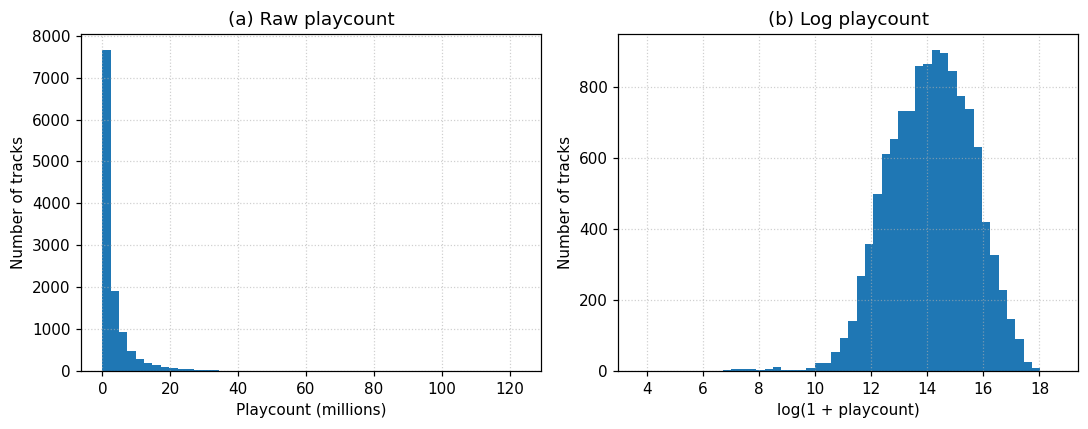

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(df["playcount"] / 1000000, bins=50)
plt.xlabel("Playcount (millions)")
plt.ylabel("Number of tracks")
plt.title("(a) Raw playcount")
plt.subplot(1, 2, 2)
plt.hist(df["log_playcount"], bins=50)
plt.xlabel("log(1 + playcount)")
plt.ylabel("Number of tracks")
plt.title("(b) Log playcount")
plt.tight_layout()
plt.savefig("figures/fig1_target_distribution.png")
plt.show()

artist_length               -0.119
word_count_name             -0.099
name_length                 -0.087
artist_word_count           -0.082
artist_is_collab            -0.064
rank_in_genre               -0.025
name_has_paren              -0.010
duration_min                -0.009
is_featured                  0.007
name_equals_album            0.016
name_has_digit               0.026
name_is_ascii                0.032
artist_bio_length            0.139
has_album                    0.158
artist_on_tour               0.203
artist_playcount             0.373
artist_plays_per_listener    0.387
has_wiki                     0.548
artist_listeners             0.558
wiki_length                  0.573
n_track_tags                 0.621
log_artist_listeners         0.638
Name: log_playcount, dtype: float64


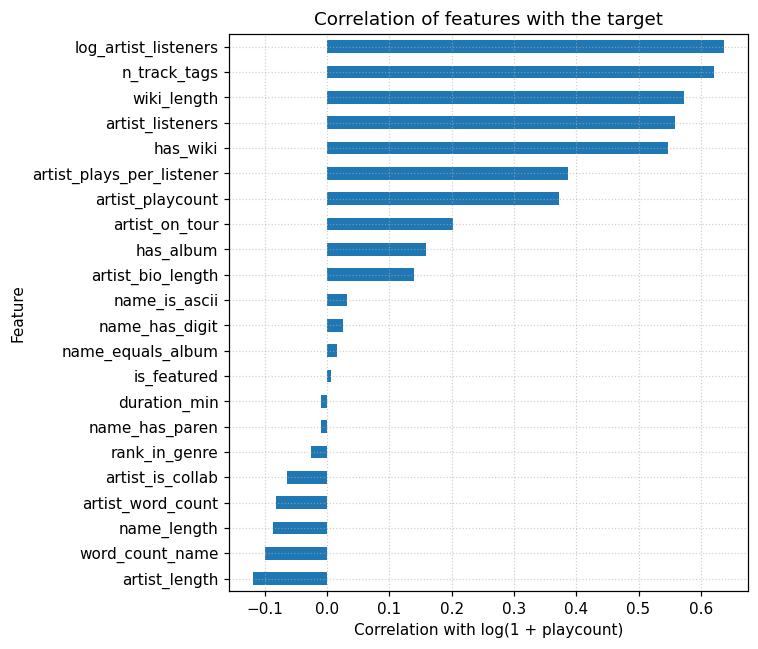

In [ ]:
num_df = df.drop(columns=["playcount", "track_id", "artist_id", "genre_tag", "collected_at"])
corr = num_df.corr()["log_playcount"].drop("log_playcount").sort_values()
print(corr.round(3))
corr.plot(kind="barh", figsize=(7, 6))
plt.xlabel("Correlation with log(1 + playcount)")
plt.ylabel("Feature")
plt.title("Correlation of features with the target")
plt.tight_layout()
plt.savefig("figures/fig2_correlations.png")
plt.show()

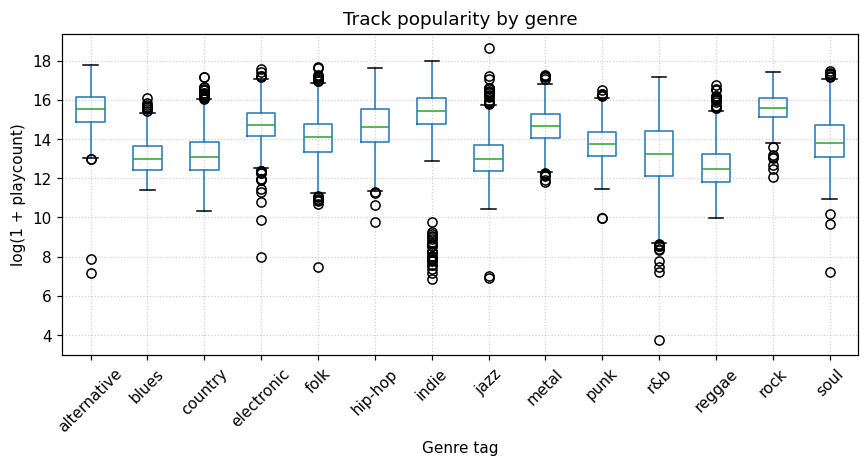

In [ ]:
df.boxplot(column="log_playcount", by="genre_tag", rot=45, figsize=(8, 4.5))
plt.xlabel("Genre tag")
plt.ylabel("log(1 + playcount)")
plt.title("Track popularity by genre")
plt.suptitle("")
plt.tight_layout()
plt.savefig("figures/fig3_genre_boxplot.png")
plt.show()

## 2. Preprocessing and split by artist

In [ ]:

df["log_artist_playcount"] = np.log1p(df["artist_playcount"])
df["log_wiki_length"] = np.log1p(df["wiki_length"])

groups = df["artist_id"]
drop_cols = ["track_id", "artist_id", "collected_at", "playcount", "log_playcount",
             "artist_playcount", "wiki_length", "artist_listeners"]
X = df.drop(columns=drop_cols)
y = df["log_playcount"]


X = pd.get_dummies(X, columns=["genre_tag"], drop_first=True, dtype=float)
print("Reference genre (dropped):", sorted(df["genre_tag"].unique())[0])
print("Number of predictors after encoding:", X.shape[1])

Reference genre (dropped): alternative
Number of predictors after encoding: 34


In [ ]:
# 80/20 split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

med_duration = X_train["duration_min"].median()
X_train["duration_min"] = X_train["duration_min"].fillna(med_duration)
X_test["duration_min"] = X_test["duration_min"].fillna(med_duration)
print("Train:", X_train.shape, "| Test:", X_test.shape,
      "| train artists:", groups.iloc[train_idx].nunique(), "| test artists:", groups.iloc[test_idx].nunique())
print("NaN left:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))

Train: (9804, 34) | Test: (2231, 34) | train artists: 2011 | test artists: 503
NaN left: 0


MODELS


In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

r2_test = r2_score(y_test, pred_test)
n = len(y_test)
p = X_test.shape[1]
adj_r2_test = 1 - (1 - r2_test) * (n - 1) / (n - p - 1)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
mae = mean_absolute_error(y_test, pred_test)
print("OLS: train R2 =", round(r2_score(y_train, pred_train), 3), "| test R2 =", round(r2_test, 3), "| adjusted R2 =", round(adj_r2_test, 3))
print("OLS: test RMSE =", round(rmse, 3), "| test MAE =", round(mae, 3), "| exp(RMSE) =", round(np.exp(rmse), 2))

# Baseline
baseline = np.full(len(y_test), y_train.mean())
print("Baseline: test R2 =", round(r2_score(y_test, baseline), 3), "| test RMSE =", round(np.sqrt(mean_squared_error(y_test, baseline)), 3))

OLS: train R2 = 0.742 | test R2 = 0.714 | adjusted R2 = 0.709
OLS: test RMSE = 0.786 | test MAE = 0.611 | exp(RMSE) = 2.19
Baseline: test R2 = -0.006 | test RMSE = 1.473


OLS in statsmodels

In [ ]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())
pred_sm = ols.predict(sm.add_constant(X_test, has_constant="add"))
print("Test R2 (statsmodels): %.3f | RMSE: %.3f" % (r2_score(y_test, pred_sm), np.sqrt(mean_squared_error(y_test, pred_sm))))

                            OLS Regression Results                            
Dep. Variable:          log_playcount   R-squared:                       0.742
Model:                            OLS   Adj. R-squared:                  0.741
Method:                 Least Squares   F-statistic:                     825.3
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:41:36   Log-Likelihood:                -11202.
No. Observations:                9804   AIC:                         2.247e+04
Df Residuals:                    9769   BIC:                         2.272e+04
Df Model:                          34                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

Diagnostics

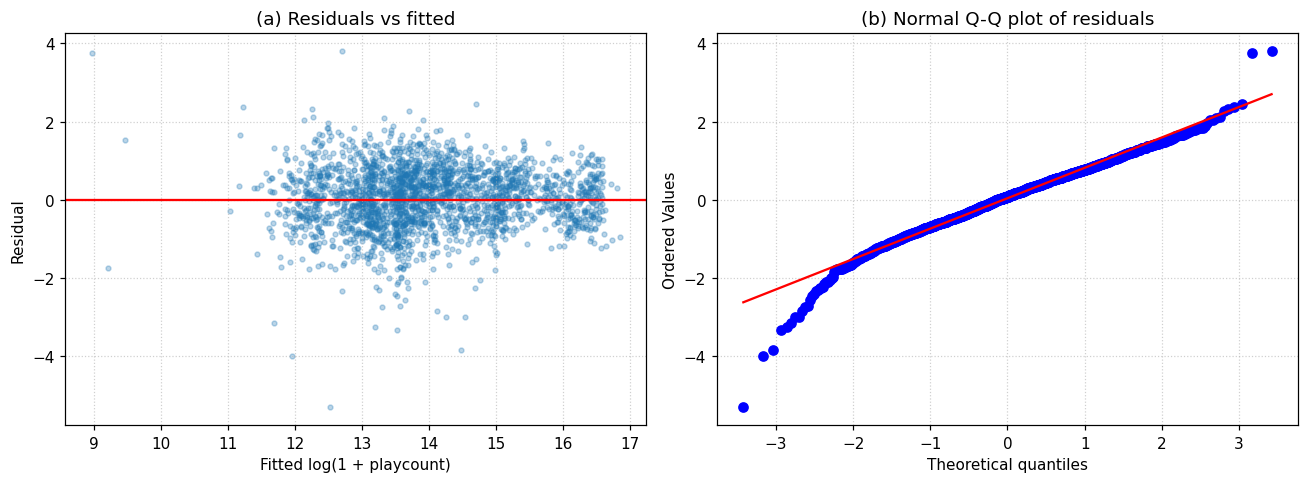

Residual skewness: -0.47 | excess kurtosis: 2.28


In [ ]:
from scipy import stats
resid = y_test - pred_sm
plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
plt.scatter(pred_sm, resid, alpha=0.3, s=10)
plt.axhline(0, color="red")
plt.xlabel("Fitted log(1 + playcount)")
plt.ylabel("Residual")
plt.title("(a) Residuals vs fitted")
plt.subplot(1, 2, 2)
stats.probplot(resid, dist="norm", plot=plt)
plt.title("(b) Normal Q-Q plot of residuals")
plt.tight_layout()
plt.savefig("figures/fig5_residual_diagnostics.png")
plt.show()
print("Residual skewness:", round(resid.skew(), 2), "| excess kurtosis:", round(resid.kurt(), 2))

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan
bp = het_breuschpagan(ols.resid, ols.model.exog)
print("Breusch-Pagan: LM =", round(bp[0], 1), "| p-value =", bp[1])

Xc = sm.add_constant(X_train)
print("Features with VIF > 5:")
for i, col in enumerate(Xc.columns):
    if col != "const":
        vif = variance_inflation_factor(Xc.values, i)
        if vif > 5:
            print(col, round(vif, 1))

Breusch-Pagan: LM = 1919.2 | p-value = 0.0
Features with VIF > 5:
name_length 6.4
word_count_name 5.9
has_wiki 68.7
log_artist_listeners 16.2
log_artist_playcount 23.1
log_wiki_length 70.6


 Robustness checks

In [ ]:
drop = ["has_wiki", "log_artist_playcount"]
X_train_small = X_train.drop(columns=drop)
X_test_small = X_test.drop(columns=drop)

model_small = sm.OLS(y_train, sm.add_constant(X_train_small)).fit()
pred_small = model_small.predict(sm.add_constant(X_test_small, has_constant="add"))
print("Without has_wiki and log_artist_playcount: test R2 = %.3f" % r2_score(y_test, pred_small))

Xc = sm.add_constant(X_train_small)
vif_small = [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]
print("Largest VIF:", round(max(vif_small), 1))

Without has_wiki and log_artist_playcount: test R2 = 0.711
Largest VIF: 6.4


In [ ]:

X_raw = X.drop(columns=["log_artist_playcount", "log_wiki_length"])
X_raw["artist_listeners"] = df["artist_listeners"]
X_raw["artist_playcount"] = df["artist_playcount"]
X_raw["wiki_length"] = df["wiki_length"]

X_raw_train = X_raw.iloc[train_idx].copy()
X_raw_test = X_raw.iloc[test_idx].copy()
X_raw_train["duration_min"] = X_raw_train["duration_min"].fillna(med_duration)
X_raw_test["duration_min"] = X_raw_test["duration_min"].fillna(med_duration)

model_raw = sm.OLS(y_train, sm.add_constant(X_raw_train)).fit()
pred_raw = model_raw.predict(sm.add_constant(X_raw_test, has_constant="add"))
print("Raw predictors: test R2 = %.3f" % r2_score(y_test, pred_raw))
print(model_raw.params[["artist_listeners", "artist_playcount", "wiki_length"]])
print(df[["artist_listeners", "artist_playcount", "wiki_length"]].corrwith(df["log_playcount"]).round(3))

Raw predictors: test R2 = 0.703
artist_listeners   -1.095468e-07
artist_playcount   -3.284591e-10
wiki_length         8.474465e-04
dtype: float64
artist_listeners    0.558
artist_playcount    0.373
wiki_length         0.573
dtype: float64


Descriptive analysis

In [ ]:
desc_cols = ["playcount", "artist_listeners", "duration_min", "n_track_tags", "wiki_length"]
print(df[desc_cols].describe().round(2))

per_artist = df["artist_id"].value_counts()
print("Tracks per artist: mean", round(per_artist.mean(), 2), "| median", per_artist.median(), "| max", per_artist.max())
print("Artists with 1 track (%):", round(100 * (per_artist == 1).mean(), 1))
print("Artists with <= 3 tracks (%):", round(100 * (per_artist <= 3).mean(), 1))
top10 = per_artist.head(len(per_artist) // 10)
print("Top 10% of artists give this % of tracks:", round(100 * top10.sum() / len(df), 1))

tags = df[df["n_track_tags"] > 0]
no_tags = df[df["n_track_tags"] == 0]
print("Tracks with tags (%):", round(100 * len(tags) / len(df), 1))
print("Median playcount with tags:", tags["playcount"].median(), "| without tags:", no_tags["playcount"].median())
print(df.groupby("genre_tag")["log_playcount"].median().sort_values().round(2))

          playcount  artist_listeners  duration_min  n_track_tags  wiki_length
count  1.203500e+04          12035.00      11714.00      12035.00     12035.00
mean   3.455046e+06        2681320.37          4.05          0.96       266.32
std    5.579038e+06        2110225.60          1.81          1.97       265.44
min    4.100000e+01            805.00          0.17          0.00         0.00
25%    4.720010e+05         936301.00          3.18          0.00         0.00
50%    1.426212e+06        2181423.00          3.80          0.00       200.00
75%    3.989830e+06        4060172.00          4.57          0.00       558.00
max    1.230759e+08        9314925.00        100.30          5.00       703.00
Tracks per artist: mean 4.79 | median 2.0 | max 129
Artists with 1 track (%): 47.0
Artists with <= 3 tracks (%): 69.9
Top 10% of artists give this % of tracks: 53.6
Tracks with tags (%): 19.2
Median playcount with tags: 8689291.0 | without tags: 964023.0
genre_tag
reggae         12.47
blu

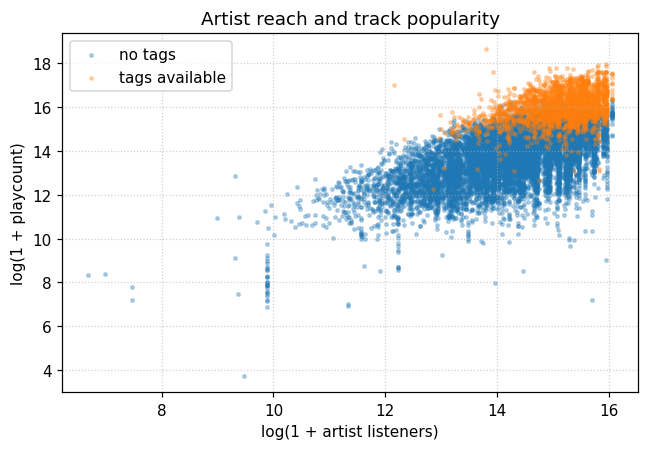

corr (no tags): 0.6
corr (tags): 0.36


In [ ]:
tags = df[df["n_track_tags"] > 0]
no_tags = df[df["n_track_tags"] == 0]
plt.figure(figsize=(6, 4.2))
plt.scatter(no_tags["log_artist_listeners"], no_tags["log_playcount"], s=5, alpha=0.3, label="no tags")
plt.scatter(tags["log_artist_listeners"], tags["log_playcount"], s=5, alpha=0.3, label="tags available")
plt.xlabel("log(1 + artist listeners)")
plt.ylabel("log(1 + playcount)")
plt.title("Artist reach and track popularity")
plt.legend()
plt.tight_layout()
plt.savefig("figures/fig6_artist_reach_scatter.png")
plt.show()
print("corr (no tags):", round(no_tags["log_artist_listeners"].corr(no_tags["log_playcount"]), 2))
print("corr (tags):", round(tags["log_artist_listeners"].corr(tags["log_playcount"]), 2))

Final analyses

Feature groups

In [ ]:
def test_model(cols):
    model = sm.OLS(y_train, sm.add_constant(X_train[cols])).fit()
    pred = model.predict(sm.add_constant(X_test[cols], has_constant="add"))
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    return r2, rmse

title_f = ["name_length", "word_count_name", "is_featured", "name_has_paren", "name_has_digit", "name_is_ascii", "name_equals_album"]
artname_f = ["artist_length", "artist_word_count", "artist_is_collab"]
artstat_f = ["log_artist_listeners", "log_artist_playcount", "artist_plays_per_listener", "artist_bio_length", "artist_on_tour"]
meta_f = ["duration_min", "has_album", "n_track_tags", "has_wiki", "log_wiki_length"]
genre_cols = [c for c in X_train.columns if c.startswith("genre_tag_")]
genre_f = ["rank_in_genre"] + genre_cols

feature_sets = [
    ("A: title and artist name", title_f + artname_f),
    ("B: A + artist statistics", title_f + artname_f + artstat_f),
    ("C: B + track metadata", title_f + artname_f + artstat_f + meta_f),
    ("D: C + genre and rank (full model)", title_f + artname_f + artstat_f + meta_f + genre_f),
]
for name, cols in feature_sets:
    r2, rmse = test_model(cols)
    print(name, "| predictors:", len(cols), "| test R2 = %.3f | RMSE = %.3f" % (r2, rmse))

A: title and artist name | predictors: 10 | test R2 = 0.012 | RMSE = 1.460
B: A + artist statistics | predictors: 15 | test R2 = 0.421 | RMSE = 1.118
C: B + track metadata | predictors: 20 | test R2 = 0.651 | RMSE = 0.868
D: C + genre and rank (full model) | predictors: 34 | test R2 = 0.714 | RMSE = 0.786


Split by artist vs. random split, and leakage chec

In [ ]:
from sklearn.model_selection import train_test_split

# Random split: the same artist can be in train and test
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
Xr_train = Xr_train.copy()
Xr_test = Xr_test.copy()
med_r = Xr_train["duration_min"].median()
Xr_train["duration_min"] = Xr_train["duration_min"].fillna(med_r)
Xr_test["duration_min"] = Xr_test["duration_min"].fillna(med_r)

model_r = sm.OLS(yr_train, sm.add_constant(Xr_train)).fit()
pred_r = model_r.predict(sm.add_constant(Xr_test, has_constant="add"))
print("Random split   : test R2 = %.3f" % r2_score(yr_test, pred_r))
print("Split by artist: test R2 = %.3f" % test_model(list(X_train.columns))[0])

# Leakage check: remove features made from the artist's play count
all_cols = list(X_train.columns)
cols_1 = list(X_train.drop(columns=["log_artist_playcount"]).columns)
cols_2 = list(X_train.drop(columns=["log_artist_playcount", "artist_plays_per_listener"]).columns)
cols_3 = list(X_train.drop(columns=artstat_f).columns)
print("Full model: test R2 =", round(test_model(all_cols)[0], 3))
print("Without log_artist_playcount: test R2 =", round(test_model(cols_1)[0], 3))
print("Without log_artist_playcount and plays per listener: test R2 =", round(test_model(cols_2)[0], 3))
print("Without all artist statistics: test R2 =", round(test_model(cols_3)[0], 3))

Random split   : test R2 = 0.751
Split by artist: test R2 = 0.714
Full model: test R2 = 0.714
Without log_artist_playcount: test R2 = 0.711
Without log_artist_playcount and plays per listener: test R2 = 0.707
Without all artist statistics: test R2 = 0.642


 Final model

In [ ]:
final_cols = list(X_train.drop(columns=["has_wiki", "log_artist_playcount"]).columns)
ols_f = sm.OLS(y_train, sm.add_constant(X_train[final_cols])).fit()
pred_f = ols_f.predict(sm.add_constant(X_test[final_cols], has_constant="add"))
print("Final model:", len(final_cols), "predictors")
print("train R2 =", round(ols_f.rsquared, 3), "| test R2 =", round(r2_score(y_test, pred_f), 3))
print("test RMSE =", round(np.sqrt(mean_squared_error(y_test, pred_f)), 3), "| test MAE =", round(mean_absolute_error(y_test, pred_f), 3))
print(ols_f.params.round(3))

Final model: 32 predictors
train R2 = 0.738 | test R2 = 0.711
test RMSE = 0.79 | test MAE = 0.614
const                        6.556
rank_in_genre               -0.001
name_length                 -0.005
artist_length               -0.000
word_count_name             -0.008
artist_word_count           -0.023
is_featured                  0.130
name_has_paren              -0.006
name_has_digit              -0.046
name_is_ascii               -0.279
artist_is_collab             0.036
name_equals_album            0.199
duration_min                -0.039
has_album                    1.662
n_track_tags                 0.238
artist_bio_length            0.001
artist_on_tour               0.012
artist_plays_per_listener    0.002
log_artist_listeners         0.398
log_wiki_length              0.103
genre_tag_blues             -0.879
genre_tag_country           -0.842
genre_tag_electronic        -0.047
genre_tag_folk              -0.274
genre_tag_hip-hop           -0.301
genre_tag_indie            

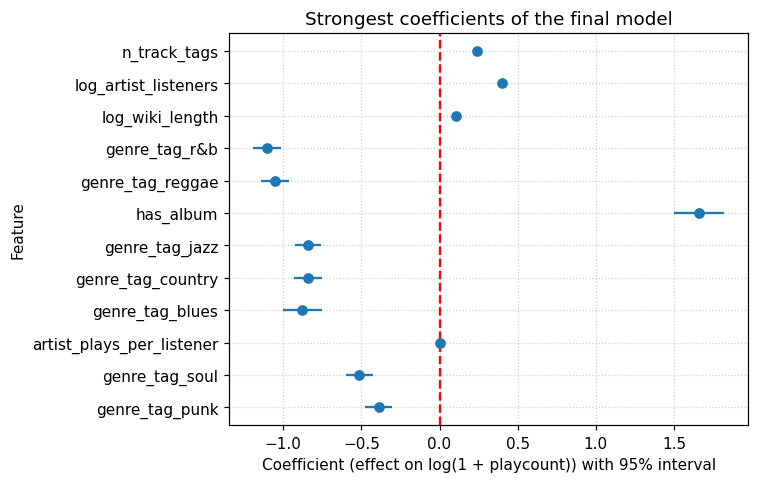

genre_tag_punk              -0.388
genre_tag_soul              -0.515
artist_plays_per_listener    0.002
genre_tag_blues             -0.879
genre_tag_country           -0.842
genre_tag_jazz              -0.842
has_album                    1.662
genre_tag_reggae            -1.053
genre_tag_r&b               -1.106
log_wiki_length              0.103
log_artist_listeners         0.398
n_track_tags                 0.238
dtype: float64


In [ ]:
t = ols_f.tvalues.drop("const")
top = t.abs().sort_values().tail(12).index
coef = ols_f.params[top]
ci = ols_f.conf_int().loc[top]
err = coef - ci[0]
plt.figure(figsize=(7, 4.5))
plt.errorbar(coef, range(12), xerr=err, fmt="o")
plt.yticks(range(12), top)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Coefficient (effect on log(1 + playcount)) with 95% interval")
plt.ylabel("Feature")
plt.title("Strongest coefficients of the final model")
plt.tight_layout()
plt.savefig("figures/fig7_final_coefficients.png")
plt.show()
print(coef.round(3))

 Outliers

In [ ]:
# Outliers
long_tr = X_train["duration_min"] > 20
print("Tracks longer than 20 min in training set:", int(long_tr.sum()))

Tracks longer than 20 min in training set: 6
